# Prédiction des prix de l'immobilier
Projet Machine Learning, Master BDA/IA. Jeu de données : Kaggle House Prices (Ames, Iowa).

# Partie 1 : projet de base

In [1]:
import pandas as pd # pandas : le tableur (lire, trier, nettoyer les données)
import numpy as np # numpy : la calculatrice (calcul sur les grands tableaux)
import matplotlib.pyplot as plt # le croyon (graphiques)
import seaborn as sns # les couleurs (graphiques plus jolie)

In [2]:
# ici on va installer tous les modules dont nous avons besoin
%pip install pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [3]:
# ici pd lit le fichier csv et df range le tableau
df = pd.read_csv("train.csv")

## Étape 1 : charger et découvrir les données

In [4]:
# (nombre de lignes, nombre de colonnes)
df.shape

(1460, 81)

In [5]:
# les 5 premières lignes( ici chaque ligne est une maison)
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [6]:
df["SalePrice"].describe() # résumé statistique des prix 

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

<Axes: xlabel='SalePrice', ylabel='Count'>

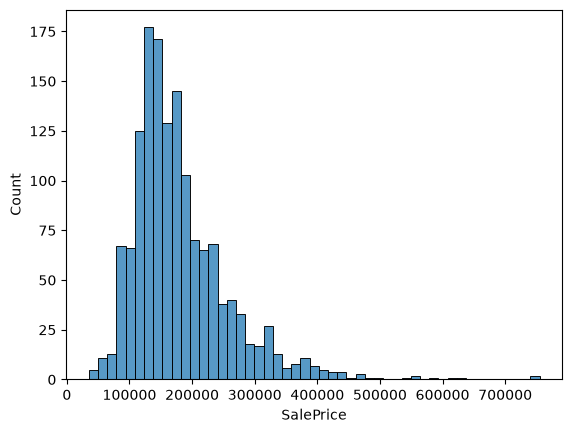

In [7]:
sns.histplot(df["SalePrice"])   # histogramme : combien de maisons dans chaque tranche de prix
# Lecture : la grosse masse est entre 100 000 et 200 000 $.
# La queue s'étire à droite jusqu'à 755 000 $ : distribution asymétrique à droite.
# Conséquence : moyenne (180 921 $) > médiane (163 000 $), car la moyenne suit la queue.

## Étape 2 : nettoyage des données

### Deux sens possibles pour une case vide
- **Donnée perdue** : la valeur existe mais n'a pas été notée (ex. LotFrontage). On peut l'estimer.
- **Absence** : l'équipement n'existe pas (ex. PoolQC : pas de piscine). Le vide est une vraie information.

 ### Étape 2.1 : compter les cases vides, colonne par colonne

In [8]:
df.isnull().sum()   # isnull() : chaque case est-elle vide ? (vrai/faux)
                    # sum()    : additionne les "vrai", donc le nombre de cases vides par colonne

Id                 0
MSSubClass         0
MSZoning           0
LotFrontage      259
LotArea            0
                ... 
MoSold             0
YrSold             0
SaleType           0
SaleCondition      0
SalePrice          0
Length: 81, dtype: int64

In [9]:
# Jupyter coupe l'affichage au milieu (le "..."), donc on filtre pour ne voir que les colonnes concernées

In [10]:
manquantes = df.isnull().sum()                          # nombre de cases vides pour chaque colonne, rangé dans "manquantes"
manquantes[manquantes > 0].sort_values(ascending=False) # on ne garde que les colonnes qui ont au moins 1 case vide,
                                                        # puis on les classe de la plus vide à la moins vide

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

### Étape 2.2 : remplacer le NaN par ce qu’il veut dire

In [11]:
# Dans PoolQC, NaN veut dire "pas de piscine" (NA = No Pool dans data_description.txt),
# ce n'est PAS une donnée perdue. On écrit donc cette information noir sur blanc.
df["PoolQC"] = df["PoolQC"].fillna("Aucune")   # fillna : remplit les cases vides avec "Aucune"
                                               # à gauche du = : on remet le résultat dans la même colonne

In [12]:
df["PoolQC"].value_counts()   # compte combien de fois chaque valeur apparaît dans la colonne

PoolQC
Aucune    1453
Gd           3
Ex           2
Fa           2
Name: count, dtype: int64

### Étape 2.3 : appliquer la même idée aux autres colonnes

In [13]:
# Colonnes où NaN veut dire "n'existe pas" (vérifié dans data_description.txt) :
# pas de ruelle, pas de clôture, pas de cheminée, pas de garage, pas de sous-sol, etc.
colonnes_absence = ["MiscFeature", "Alley", "Fence", "FireplaceQu",
                    "GarageType", "GarageFinish", "GarageQual", "GarageCond",
                    "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"]
                    # une liste = plusieurs noms entre [ ] séparés par des virgules

# df[colonnes_absence] : "prends ces colonnes d'un coup"
# .fillna("Aucune")    : remplace les cases vides par "Aucune"
# le = à gauche remet le résultat dans les mêmes colonnes
df[colonnes_absence] = df[colonnes_absence].fillna("Aucune")

In [14]:
# On recompte les cases vides : il ne doit rester que les colonnes du groupe B
manquantes = df.isnull().sum()
manquantes[manquantes > 0].sort_values(ascending=False)

MasVnrType     872
LotFrontage    259
GarageYrBlt     81
MasVnrArea       8
Electrical       1
dtype: int64

### Étape 2.4 : LotFrontage (259 cases vides)

moyenne : 70.04995836802665
médiane : 69.0


<Axes: xlabel='LotFrontage', ylabel='Count'>

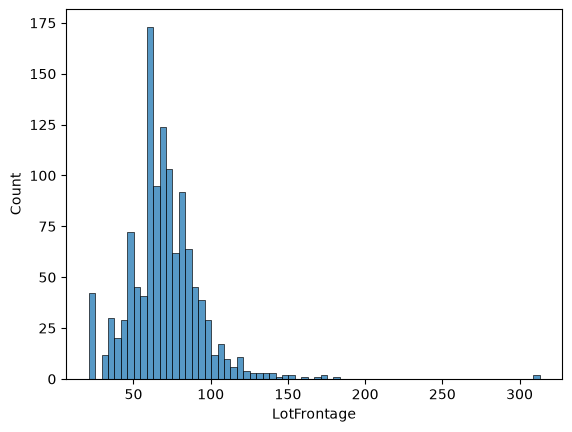

In [15]:
# Moyenne et médiane de LotFrontage (les cases vides sont ignorées dans le calcul)
print("moyenne :", df["LotFrontage"].mean())
print("médiane :", df["LotFrontage"].median())
# Moyenne > médiane  => queue vers le haut (asymétrie à droite)
# Moyenne < médiane  => queue vers le bas (asymétrie à gauche)

# L'histogramme montre la queue : regarde de quel côté ça s'étire
sns.histplot(df["LotFrontage"])

In [16]:
# LotFrontage : 259 cases vides = vraies données perdues (toute maison a une façade).
# On les remplace par la valeur typique de la colonne.
mediane = df["LotFrontage"].median()   # median() : la valeur du milieu, ignore les cases vides
                                       # (on la range dans la boîte "mediane")
df["LotFrontage"] = df["LotFrontage"].fillna(mediane)   # fillna : remplit les cases vides avec la médiane
                                                        # le = à gauche remet le résultat dans la colonne

In [17]:
df["LotFrontage"]   # affiche la colonne LotFrontage (une valeur par maison)

0       65.0
1       80.0
2       68.0
3       60.0
4       84.0
        ... 
1455    62.0
1456    85.0
1457    66.0
1458    68.0
1459    75.0
Name: LotFrontage, Length: 1460, dtype: float64

In [18]:
df["LotFrontage"].head(10)          # les 10 premières valeurs seulement

0    65.0
1    80.0
2    68.0
3    60.0
4    84.0
5    85.0
6    75.0
7    69.0
8    51.0
9    50.0
Name: LotFrontage, dtype: float64

In [19]:
df["LotFrontage"].tail(10)          # les 10 dernières valeurs

1450    60.0
1451    78.0
1452    35.0
1453    90.0
1454    62.0
1455    62.0
1456    85.0
1457    66.0
1458    68.0
1459    75.0
Name: LotFrontage, dtype: float64

In [20]:
print(df["LotFrontage"].to_string())   # TOUTES les valeurs (1460 lignes, ça défile longtemps)

0        65.0
1        80.0
2        68.0
3        60.0
4        84.0
5        85.0
6        75.0
7        69.0
8        51.0
9        50.0
10       70.0
11       85.0
12       69.0
13       91.0
14       69.0
15       51.0
16       69.0
17       72.0
18       66.0
19       70.0
20      101.0
21       57.0
22       75.0
23       44.0
24       69.0
25      110.0
26       60.0
27       98.0
28       47.0
29       60.0
30       50.0
31       69.0
32       85.0
33       70.0
34       60.0
35      108.0
36      112.0
37       74.0
38       68.0
39       65.0
40       84.0
41      115.0
42       69.0
43       69.0
44       70.0
45       61.0
46       48.0
47       84.0
48       33.0
49       66.0
50       69.0
51       52.0
52      110.0
53       68.0
54       60.0
55      100.0
56       24.0
57       89.0
58       66.0
59       60.0
60       63.0
61       60.0
62       44.0
63       50.0
64       69.0
65       76.0
66       69.0
67       72.0
68       47.0
69       81.0
70       95.0
71    

### Étape 2.5 : GarageYrBlt

In [21]:
# GarageYrBlt : 81 cases vides = maisons SANS garage (comme GarageType). C'est une absence.
# Colonne de nombres : on ne peut pas écrire "Aucune". On met l'année de construction de la maison,
# valeur neutre. L'info "pas de garage" reste portée par GarageType = "Aucune".
df["GarageYrBlt"] = df["GarageYrBlt"].fillna(df["YearBuilt"])
# fillna(une colonne) : chaque case vide reçoit la valeur de YearBuilt DE LA MÊME LIGNE (la même maison)

In [22]:
# Doit afficher 0 : plus aucune case vide dans GarageYrBlt
df["GarageYrBlt"].isnull().sum()

np.int64(0)

### Étape 2.6 : MasVnrType (872 cases vides)

In [23]:
# MasVnrType : 872 cases vides. En réalité 864 sont le mot "None" du fichier (= pas de placage),
# que pandas a pris pour une case vide. Seules 8 sont vraiment manquantes.
# "None" étant la valeur la plus fréquente, on remplit les 872 avec "Aucune" (même mot que pour les autres absences).
df["MasVnrType"] = df["MasVnrType"].fillna("Aucune")   # fillna : remplit les cases vides
                                                       # le = à gauche remet le résultat dans la colonne

In [24]:
# Compte chaque valeur : tu dois voir "Aucune" avec 872, puis BrkFace, Stone, BrkCmn
df["MasVnrType"].value_counts()

MasVnrType
Aucune     872
BrkFace    445
Stone      128
BrkCmn      15
Name: count, dtype: int64

### Étape 2.7 : MasVnrArea (8 cases vides)

In [25]:
# MasVnrArea : 8 cases vides, les mêmes maisons que les 8 manquantes de MasVnrType (qu'on a mises à "Aucune").
# Pas de placage = surface de 0 pied carré : le zéro est ici un vrai sens (contrairement à une année).
df["MasVnrArea"] = df["MasVnrArea"].fillna(0)   # fillna(0) : les cases vides deviennent 0
                                                # le = à gauche remet le résultat dans la colonne

In [26]:
# Doit afficher 0 : plus aucune case vide dans MasVnrArea
df["MasVnrArea"].isnull().sum()

np.int64(0)

### Étape 2.8 : Electrical (1 seule case vide)

In [27]:
# Electrical : 1 seule case vide. Toute maison a un système électrique : c'est une donnée perdue, pas une absence.
# On la remplace par la valeur la plus fréquente de la colonne (le mode), ici SBrkr pour plus de 9 maisons sur 10.
mode = df["Electrical"].mode()[0]   # mode() : la ou les valeurs les plus fréquentes (renvoyées dans une liste)
                                    # [0] : on prend la première de cette liste
df["Electrical"] = df["Electrical"].fillna(mode)   # fillna : remplit la case vide avec le mode
                                                   # le = à gauche remet le résultat dans la colonne

In [28]:
mode   # doit afficher 'SBrkr'

'SBrkr'

In [29]:
# Total de cases vides dans TOUT le tableau : doit afficher 0
df.isnull().sum().sum()

np.int64(0)

### Étape 2.9 : les doublons

In [30]:
# duplicated() : pour chaque ligne, dit "cette ligne est-elle identique à une ligne déjà vue ?" (vrai/faux)
# sum()        : additionne les "vrai", donc le nombre de lignes en double
df.duplicated().sum()

np.int64(0)

### Étape 2.10 : les valeurs aberrantes

<Axes: xlabel='GrLivArea', ylabel='SalePrice'>

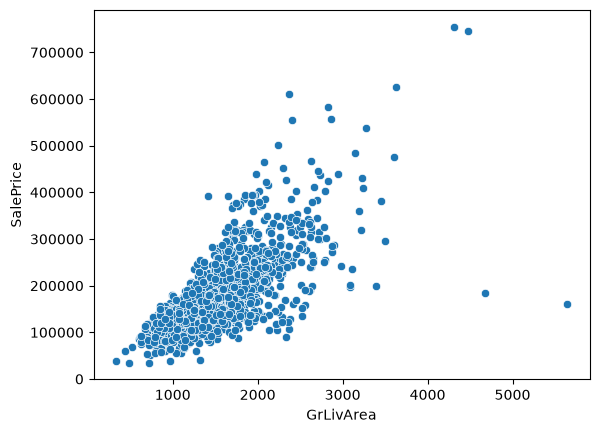

In [31]:
# Nuage de points : chaque point est une maison.
# x = surface habitable (GrLivArea), y = prix de vente (SalePrice).
# On cherche les maisons qui s'éloignent du nuage principal : ce sont des valeurs aberrantes possibles.
sns.scatterplot(x=df["GrLivArea"], y=df["SalePrice"])
# scatterplot : "trace un nuage de points"
# x= et y= : quelle colonne va sur quel axe

### Étape 2.11 : isoler les deux suspectes

In [32]:
# On cherche les maisons à la fois TRÈS grandes (plus de 4000 pieds carrés) ET peu chères (moins de 300 000 $).
# df["GrLivArea"] > 4000  : vrai pour chaque maison de plus de 4000 pieds carrés
# df["SalePrice"] < 300000: vrai pour chaque maison à moins de 300 000 $
# & : "ET" : il faut que les deux conditions soient vraies (chaque condition entre parenthèses)
suspectes = df[(df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)]
# df[ ... ] : on ne garde que les lignes pour lesquelles la condition est vraie

suspectes[["Id", "GrLivArea", "SalePrice"]]   # on affiche seulement 3 colonnes pour que ce soit lisible

,Id,GrLivArea,SalePrice
523,524,4676,184750
1298,1299,5642,160000


### Étape 2.12 : retirer ces deux maisons

In [33]:
# On supprime les 2 maisons aberrantes (Id 524 et 1299) : très grandes mais peu chères,
# elles contredisent la tendance "plus grand = plus cher" et fausseraient l'apprentissage.
# suspectes.index : les numéros de ligne des 2 maisons trouvées juste avant
# drop(...)       : "retire ces lignes du tableau"
df = df.drop(suspectes.index)   # le = à gauche remet le tableau sans ces lignes dans df

In [34]:
# Avant : 1460 lignes. Après : on doit avoir 2 lignes de moins.
df.shape

(1458, 81)

### Étape 2.13 : revérifier le nuage de points

np.int64(4476)

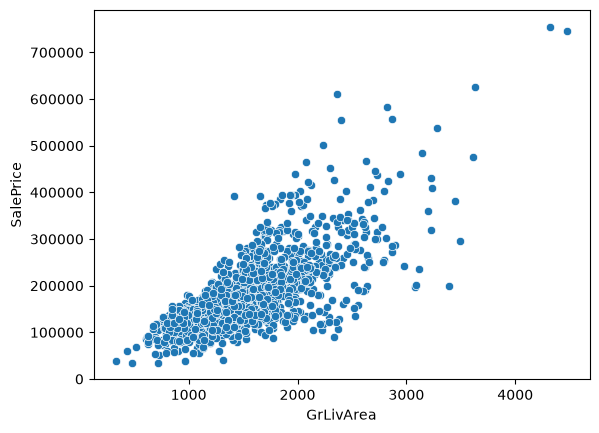

In [35]:
# On retrace le même nuage de points, mais sur le tableau SANS les 2 maisons aberrantes.
# x = surface habitable (GrLivArea), y = prix de vente (SalePrice)
sns.scatterplot(x=df["GrLivArea"], y=df["SalePrice"])

# Pour vérifier chiffre en main : la plus grande surface qui reste.
# max() : la valeur la plus grande de la colonne
df["GrLivArea"].max()   # avant : 5642. Après suppression : on doit trouver 4476

## Étape 3 : préparer les variables

### Étape 3.1 : séparer X et y

In [36]:
# y = la réponse à prédire (le prix), rangée à part comme un corrigé
y = df["SalePrice"]

# X = tous les indices. drop(columns=[...]) : "retire ces colonnes".
# On retire SalePrice (sinon le modèle lirait la réponse) et Id (un simple numéro de ligne, sans lien avec le prix).
X = df.drop(columns=["SalePrice", "Id"])

In [37]:
# On regarde les dimensions de X et de y pour vérifier la séparation
print(X.shape)   # attendu : (1458, 79)  -> 1458 maisons, 79 indices
print(y.shape)   # attendu : (1458,)     -> 1458 prix, une seule colonne

(1458, 79)
(1458,)


### Étape 3.2 : repérer les colonnes en texte

In [38]:
# dtypes : le type de chaque colonne (nombres entiers, nombres décimaux, ou texte)
# value_counts() : compte combien de colonnes de chaque type
X.dtypes.value_counts()

str        43
int64      33
float64     3
Name: count, dtype: int64

In [39]:
# select_dtypes(exclude="number") : "garde seulement les colonnes qui ne sont PAS des nombres", donc les colonnes en texte
colonnes_texte = X.select_dtypes(exclude="number").columns   # .columns : seulement leurs noms
len(colonnes_texte)   # len : le nombre de colonnes concernées

43

In [40]:
# Les valeurs possibles de MSZoning (le type de zone) et combien de maisons dans chacune
X["MSZoning"].value_counts()

MSZoning
RL         1149
RM          218
FV           65
RH           16
C (all)      10
Name: count, dtype: int64

### Étape 3.3 : transformer le texte en nombres, l’encodage « one-hot »

In [41]:
# get_dummies : transforme une colonne de texte en plusieurs colonnes de 0 et de 1 (one-hot).
# On l'essaie sur MSZoning seule, pour comprendre le principe.
# dtype=int : on veut des 0 et des 1 (et pas des True/False)
zones = pd.get_dummies(X["MSZoning"], dtype=int)

zones.head()   # les 5 premières maisons : une colonne par type de zone

,C (all),FV,RH,RL,RM
0,0,0,0,1,0
1,0,0,0,1,0
2,0,0,0,1,0
3,0,0,0,1,0
4,0,0,0,1,0


In [42]:
# sum() additionne chaque colonne : comme un 1 = "oui", la somme donne le NOMBRE de maisons dans cette zone
zones.sum()
# À comparer avec X["MSZoning"].value_counts() : les nombres doivent être identiques

C (all)      10
FV           65
RH           16
RL         1149
RM          218
dtype: int64

### Étape 3.4 : l’appliquer aux 43 colonnes en texte

In [43]:
# get_dummies sur TOUT le tableau X :
# - les 43 colonnes de texte deviennent chacune plusieurs colonnes de 0 et de 1
# - les colonnes déjà numériques ne changent pas
# On range le résultat dans un NOUVEAU nom (X_enc) : on garde X intact, pour pouvoir recommencer si besoin.
X_enc = pd.get_dummies(X, dtype=int)

X_enc.shape   # nombre de lignes et de colonnes après encodage

(1458, 301)

### Étape 3.5 : mettre de côté un « examen blanc »

In [49]:
# train_test_split : on va couper les données en une partie entraînement et une partie test.
from sklearn.model_selection import train_test_split

# On sépare X (les indices) ET y (les prix) de la même façon : la maison n°5 de X garde son prix dans y.
# test_size=0.2 : 20 % des maisons vont dans l'examen blanc.
# random_state=42 : fixe le "hasard" du tirage pour obtenir la même coupe à chaque exécution
#                   (nécessaire pour retrouver les mêmes résultats d'un jour à l'autre).
X_train, X_test, y_train, y_test = train_test_split(X_enc, y, test_size=0.2, random_state=42)
# X_train, y_train : les maisons d'entraînement (indices et prix)
# X_test,  y_test  : les maisons de l'examen blanc (indices et prix)

In [45]:
 %pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [46]:
# --force-reinstall : réinstalle même si c'est déjà là, pour retélécharger un fichier propre
# --no-cache-dir    : ne réutilise pas la copie gardée en mémoire (potentiellement bloquée)
%pip install --force-reinstall --no-cache-dir scipy

   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ---------------------------------------- 0.3/37.4 MB ? eta -:--:--
    --------------------------------------- 0.5/37.4 MB 958.4 kB/s eta 0:00:39
    --------------------------------------- 0.8/37.4 MB 1.0 MB/s eta 0:00:37
    --------------------------------------- 0.8/37.4 MB 1.0 MB/s eta 0:00:37
   - -------------------------------------- 1.0/37.4 MB 895.1 kB/s eta 0:00:41
   - -------------------------------------- 1.3/37.4 MB 978.2 kB/s eta 0:00:37
   - -------------------------------------- 1.6/37.4 MB 1.0 MB/s eta 0:00:36
   - -------------------------------------- 1.8/37.4 MB 1.0 MB/s eta 0:00:35
   -- ------------------------------------- 2.1/37.4 MB 1.1 MB/s eta 0:00:33
   -- ------------------------------------- 2.4/37.4 MB 1.1 MB/s eta 0:00:34
   -- ------------------------------------- 2.4/37.4 MB 1.1 MB/s eta 0:00:34
   -- --------

  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.


In [50]:
# On essaie de charger scikit-learn et on affiche sa version.
# Si ça marche, un numéro de version s'affiche. Si Windows bloque encore, un message rouge apparaît.
import sklearn
sklearn.__version__

'1.9.1'

In [51]:
# C'est exactement la ligne qui avait échoué.
# Si elle passe sans message rouge, Windows ne bloque plus scipy : le problème est réglé.
from sklearn.model_selection import train_test_split

In [52]:
# On sépare les données : 80 % pour l'entraînement, 20 % pour l'examen blanc.
# random_state=42 : fixe le tirage au sort pour retrouver la même coupe à chaque exécution.
X_train, X_test, y_train, y_test = train_test_split(X_enc, y, test_size=0.2, random_state=42)

# On vérifie les dimensions des 4 morceaux
print(X_train.shape)   # attendu : (1166, 301)
print(X_test.shape)    # attendu : (292, 301)
print(y_train.shape)   # attendu : (1166,)
print(y_test.shape)    # attendu : (292,)

(1166, 301)
(292, 301)
(1166,)
(292,)


## Étape 4 : entraînement des modèles

### 4.1 Régression linéaire : création et entraînement

In [53]:
# On sort l'outil "régression linéaire" de la boîte à modèles scikit-learn.
from sklearn.linear_model import LinearRegression

# On crée un modèle vide : il n'a encore rien appris, ses poids ne sont pas réglés.
modele = LinearRegression()

# fit : "apprends". Le modèle reçoit les indices (X_train) ET les prix réels (y_train),
# et ajuste ses 301 poids pour se tromper le moins possible sur ces 1166 maisons.
# IMPORTANT : on n'utilise QUE les données d'entraînement. Les 292 maisons de test restent cachées.
modele.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](301,)","[ 16.19, 65.14, 0.67,..., 8207.91, 15246.64,-70185.92]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](301,)","['MSSubClass','LotFrontage','LotArea',...,'SaleCondition_Family', 'SaleCondition_Normal','SaleCondition_Partial']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,3.149e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,301
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(243)


### 4.2 Examen blanc : prédictions sur les 292 maisons de test

In [54]:
# predict : "estime le prix". On donne au modèle les indices des 292 maisons de test, SANS leur prix.
predictions = modele.predict(X_test)

# On range côte à côte le vrai prix et le prix estimé pour les 5 premières maisons de test.
# y_test.values : on prend juste les nombres (sans les numéros de ligne d'origine, qui désaligneraient le tableau)
# .round(0)     : on arrondit à l'unité, pour que ce soit lisible
comparaison = pd.DataFrame({
    "Prix réel":   y_test.values[:5],        # [:5] : les 5 premières valeurs seulement
    "Prix estimé": predictions[:5].round(0)
})
comparaison

,Prix réel,Prix estimé
0,190000,241569.0
1,100000,89147.0
2,115000,86824.0
3,159000,180445.0
4,315500,323752.0


### Étape 4.3 : mesurer l’erreur moyenne (MAE)

In [55]:
# On sort l'outil qui calcule l'erreur absolue moyenne.
from sklearn.metrics import mean_absolute_error

# On compare les VRAIS prix (y_test) avec les prix ESTIMÉS par le modèle (predictions),
# sur les 292 maisons de test. Le résultat est en dollars.
mae = mean_absolute_error(y_test, predictions)

# print affiche le résultat. round(0) : arrondi à l'unité pour que ce soit lisible.
print("MAE :", round(mae, 0), "$")

MAE : 18207.0 $


### Étape 4.4 : une mesure plus sévère, la RMSE

In [56]:
# On sort l'outil qui calcule l'erreur quadratique moyenne.
from sklearn.metrics import mean_squared_error

# mean_squared_error : élève chaque écart au carré et fait la moyenne (les gros écarts pèsent très lourd).
# ** 0.5 : racine carrée, pour revenir à des dollars (au lieu de dollars au carré).
rmse = mean_squared_error(y_test, predictions) ** 0.5

# On affiche la RMSE à côté de la MAE pour les comparer.
print("MAE  :", round(mae, 0), "$")
print("RMSE :", round(rmse, 0), "$")

MAE  : 18207.0 $
RMSE : 25759.0 $


### Étape 4.5 : le score R², une note globale

In [57]:
# On sort l'outil qui calcule le score R².
from sklearn.metrics import r2_score

# r2_score : compare les vrais prix (y_test) aux prix estimés (predictions).
# 1 = parfait ; 0 = pas mieux que de répondre toujours la moyenne.
r2 = r2_score(y_test, predictions)

print("R² :", round(r2, 3))

R² : 0.88


### Étape 4.6 : comparer le score d’entraînement et le score de test

In [58]:
# Le modèle estime les prix des 1166 maisons d'ENTRAÎNEMENT (celles qu'il a déjà vues pendant fit).
predictions_train = modele.predict(X_train)

# R² sur l'entraînement, à comparer avec le R² sur le test.
r2_train = r2_score(y_train, predictions_train)

print("R² entraînement :", round(r2_train, 3))
print("R² test         :", round(r2, 3))
print("Écart           :", round(r2_train - r2, 3))   # différence entre les deux scores

R² entraînement : 0.944
R² test         : 0.88
Écart           : 0.064


### Étape 4.7 : freiner le modèle avec Ridge

In [59]:
# On sort l'outil Ridge : une régression linéaire avec un frein sur les poids.
from sklearn.linear_model import Ridge

# alpha=10 : la force du frein (0 = aucun frein, grand = frein fort).
ridge = Ridge(alpha=10)

# fit : le modèle apprend sur les maisons d'ENTRAÎNEMENT uniquement (comme avant).
ridge.fit(X_train, y_train)

# predict : il estime les prix des maisons de TEST, qu'il n'a jamais vues.
pred_ridge = ridge.predict(X_test)

# On calcule les 3 mesures sur le test, plus le R² sur l'entraînement pour voir l'écart.
print("MAE         :", round(mean_absolute_error(y_test, pred_ridge), 0), "$")
print("RMSE        :", round(mean_squared_error(y_test, pred_ridge) ** 0.5, 0), "$")
print("R² test     :", round(r2_score(y_test, pred_ridge), 3))
print("R² entraîn. :", round(r2_score(y_train, ridge.predict(X_train)), 3))

MAE         : 16807.0 $
RMSE        : 23213.0 $
R² test     : 0.902
R² entraîn. : 0.936


### Étape 4.8 : trouver la bonne force de frein

In [60]:
# On essaie plusieurs forces de frein et on note le R² de chacune.
# Le for répète les lignes décalées pour CHAQUE valeur de la liste : alpha vaut d'abord 1, puis 10, puis 100, puis 1000.
for alpha in [1, 10, 100, 1000]:
    m = Ridge(alpha=alpha)                              # un modèle Ridge avec ce réglage de frein
    m.fit(X_train, y_train)                             # il apprend sur l'entraînement
    r2_t = r2_score(y_test, m.predict(X_test))          # R² sur le test
    r2_e = r2_score(y_train, m.predict(X_train))        # R² sur l'entraînement
    print("alpha =", alpha, "| R² test :", round(r2_t, 3), "| R² entraîn. :", round(r2_e, 3))

alpha = 1 | R² test : 0.894 | R² entraîn. : 0.942
alpha = 10 | R² test : 0.902 | R² entraîn. : 0.936
alpha = 100 | R² test : 0.899 | R² entraîn. : 0.917
alpha = 1000 | R² test : 0.868 | R² entraîn. : 0.878


### Étape 4.9 : choisir alpha sans toucher au test (validation croisée)

In [61]:
# On sort l'outil qui fait la validation croisée.
from sklearn.model_selection import cross_val_score

# Pour chaque force de frein, on fait passer 5 mini-examens sur les données d'ENTRAÎNEMENT seulement.
# Le test (X_test, y_test) n'est PAS utilisé ici.
for alpha in [1, 3, 10, 30, 100, 300, 1000]:
    # cv=5 : on coupe X_train en 5 paquets, et on fait 5 tours (un paquet différent en examen à chaque tour).
    # scoring="r2" : on note chaque mini-examen avec le R².
    notes = cross_val_score(Ridge(alpha=alpha), X_train, y_train, cv=5, scoring="r2")
    # notes : une liste de 5 R² (un par mini-examen) ; .mean() en fait la moyenne.
    print("alpha =", alpha, "| R² moyen :", round(notes.mean(), 3))

alpha = 1 | R² moyen : 0.894
alpha = 3 | R² moyen : 0.899
alpha = 10 | R² moyen : 0.902
alpha = 30 | R² moyen : 0.899
alpha = 100 | R² moyen : 0.891
alpha = 300 | R² moyen : 0.876
alpha = 1000 | R² moyen : 0.849


### Étape 4.10 : un deuxième type de modèle, la forêt aléatoire

In [63]:
# On sort l'outil "forêt aléatoire" pour la régression (estimer un nombre).
from sklearn.ensemble import RandomForestRegressor

# n_estimators=200 : la forêt contient 200 arbres.
# random_state=42  : fixe le hasard (chaque arbre voit un échantillon tiré au sort), pour retrouver les mêmes résultats.
foret = RandomForestRegressor(n_estimators=200, random_state=42)

# fit : chaque arbre apprend sur l'ENTRAÎNEMENT (peut prendre quelques secondes).
foret.fit(X_train, y_train)

# predict : estime les prix des maisons de TEST (moyenne des 200 arbres).
pred_foret = foret.predict(X_test)

# Les mêmes mesures que pour Ridge, pour pouvoir comparer.
print("MAE         :", round(mean_absolute_error(y_test, pred_foret), 0), "$")
print("RMSE        :", round(mean_squared_error(y_test, pred_foret) ** 0.5, 0), "$")
print("R² test     :", round(r2_score(y_test, pred_foret), 3))
print("R² entraîn. :", round(r2_score(y_train, foret.predict(X_train)), 3))

MAE         : 16860.0 $
RMSE        : 24262.0 $
R² test     : 0.893
R² entraîn. : 0.983


### Étape 4.11 : quelles caractéristiques font le prix ?

In [64]:
# feature_importances_ : pour chaque colonne, la part de "décisions" des 200 arbres qu'elle a servi à prendre (le total fait 1).
# pd.Series(..., index=X_train.columns) : on associe chaque importance au NOM de sa colonne.
# sort_values(ascending=False)          : on classe du plus important au moins important.
importances = pd.Series(foret.feature_importances_, index=X_train.columns).sort_values(ascending=False)

# head(10) : les 10 variables les plus importantes. round(3) : on arrondit à 3 décimales.
importances.head(10).round(3)

OverallQual     0.559
GrLivArea       0.121
TotalBsmtSF     0.061
1stFlrSF        0.026
BsmtFinSF1      0.025
2ndFlrSF        0.020
GarageArea      0.017
TotRmsAbvGrd    0.013
LotArea         0.013
FullBath        0.012
dtype: float64

## Étape 5 : évaluer le modèle final

### Étape 5.1 :construire le tableau des estimations de Ridge

In [65]:
# On construit un tableau avec le vrai prix et le prix estimé par Ridge, pour les 292 maisons de test.
# y_test.values : les vrais prix (juste les nombres)
# pred_ridge    : les prix estimés par Ridge à l'étape 4.7
# .round(0)     : on arrondit à l'unité pour que ce soit lisible
erreurs = pd.DataFrame({
    "Prix réel":   y_test.values,
    "Prix estimé": pred_ridge.round(0)
})

# Écart = estimé - réel.
# Positif : le modèle a estimé TROP HAUT. Négatif : il a estimé TROP BAS.
erreurs["Écart"] = erreurs["Prix estimé"] - erreurs["Prix réel"]

# head() : on regarde les 5 premières maisons.
erreurs.head()

,Prix réel,Prix estimé,Écart
0,190000,238720.0,48720.0
1,100000,87073.0,-12927.0
2,115000,92393.0,-22607.0
3,159000,177800.0,18800.0
4,315500,327801.0,12301.0


### Étape 5.2 : trouver les 5 pires erreurs

In [66]:
# abs() : la valeur absolue, donc l'écart sans son signe (-12927 devient 12927).
erreurs["Écart absolu"] = erreurs["Écart"].abs()

# sort_values : on trie le tableau selon "Écart absolu".
# ascending=False : du plus grand au plus petit.
# head(5) : on garde les 5 pires erreurs.
erreurs.sort_values("Écart absolu", ascending=False).head(5)

,Prix réel,Prix estimé,Écart,Écart absolu
23,200500,290110.0,89610.0,89610.0
102,244000,333139.0,89139.0,89139.0
167,276000,358954.0,82954.0,82954.0
6,311500,228604.0,-82896.0,82896.0
158,200624,267050.0,66426.0,66426.0


### Étape 5.3 : regarder ces 5 maisons de près

In [67]:
# Les 5 pires erreurs, repérées par leur position dans le tableau "erreurs" (la colonne de gauche, 23, 102...).
# X_test.index : les numéros d'origine des maisons de test, dans le même ordre que le tableau erreurs.
# Ça nous permet de retrouver ces mêmes maisons dans le tableau complet df.
pires = X_test.index[[23, 102, 167, 6, 158]]

# df.loc[lignes, colonnes] : on ne garde que ces 5 maisons et ces colonnes.
# OverallQual : qualité des matériaux (1 à 10)    OverallCond : état général (1 à 10)
# GrLivArea   : surface habitable                 Neighborhood : quartier
# SaleCondition : type de vente (Normal, Partial, Abnorml, Alloca...)
df.loc[pires, ["OverallQual", "OverallCond", "GrLivArea", "Neighborhood", "SaleCondition", "SalePrice"]]

,OverallQual,OverallCond,GrLivArea,Neighborhood,SaleCondition,SalePrice
1173,5,6,3086,ClearCr,Normal,200500
70,7,6,2223,NAmes,Normal,244000
261,8,5,2574,CollgCr,Partial,276000
218,7,9,1954,Crawfor,Normal,311500
529,6,3,2515,Crawfor,Alloca,200624


### Étape 5.4 : le bilan des trois modèles

Sur les 292 maisons de test :

| Modèle | MAE (dollars) | RMSE (dollars) | R² test | R² entraînement |
|---|---|---|---|---|
| Régression linéaire | 18 207 | 25 759 | 0,880 | 0,944 |
| **Ridge (alpha=10)** | **16 807** | **23 213** | **0,902** | 0,936 |
| Forêt aléatoire | 16 860 | 24 262 | 0,893 | 0,983 |

**Modèle retenu : Ridge (alpha=10).** Il obtient les meilleures mesures sur le test et le plus faible sur-apprentissage (écart de 0,034 entre entraînement et test, contre 0,090 pour la forêt). Les plus grosses erreurs (jusqu'à 89 000 dollars) semblent liées à des ventes atypiques et à des états extrêmes.

# Partie 2 : compléments demandés par l'énoncé
Création de nouvelles variables, normalisation et modèles supplémentaires. Les résultats se comparent à ceux de la Partie1.

## A.1 : Nouvelle variable : âge du bâtiment

In [70]:
# .copy() : une photocopie du tableau. On travaille sur df2, et df (utilisé en Partie 1) reste intact.
df2 = df.copy()

# Création d'une NOUVELLE colonne : l'âge du bâtiment au moment de la vente.
# df2["YrSold"] - df2["YearBuilt"] : année de vente moins année de construction, calculée maison par maison.
# Le nom à gauche du = (df2["AgeBatiment"]) crée la colonne.
df2["AgeBatiment"] = df2["YrSold"] - df2["YearBuilt"]

# describe() : le résumé de la nouvelle colonne (minimum, maximum, moyenne, médiane...).
df2["AgeBatiment"].describe()

count    1458.000000
mean       36.598080
std        30.240565
min         0.000000
25%         8.000000
50%        35.000000
75%        54.000000
max       136.000000
Name: AgeBatiment, dtype: float64

## A.2 : cette variable est-elle liée au prix ?

Corrélation âge / prix : -0.524


<Axes: xlabel='AgeBatiment', ylabel='SalePrice'>

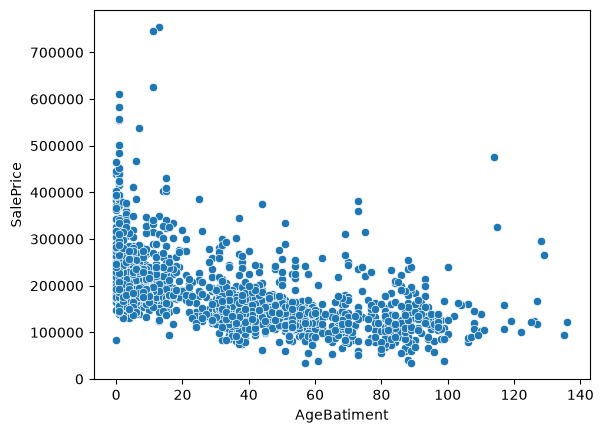

In [71]:
# corr() : calcule la corrélation entre deux colonnes (un nombre entre -1 et +1).
# Le signe donne le SENS du lien, la valeur (sans le signe) donne sa FORCE.
print("Corrélation âge / prix :", round(df2["AgeBatiment"].corr(df2["SalePrice"]), 3))

# Un nuage de points pour VOIR le lien : un point = une maison.
# x = âge du bâtiment, y = prix de vente.
sns.scatterplot(x=df2["AgeBatiment"], y=df2["SalePrice"])

## A.3 : cette variable améliore-t-elle le modèle ?

In [72]:
# Même préparation qu'en Partie 1, mais avec df2 (qui contient AgeBatiment).
# On sépare indices et réponse, on retire SalePrice et Id des indices.
X2 = df2.drop(columns=["SalePrice", "Id"])
y2 = df2["SalePrice"]

# Encodage one-hot du texte (comme à l'étape 3.4).
X2_enc = pd.get_dummies(X2, dtype=int)

# Même coupe qu'avant : 80 % entraînement, 20 % test, avec le même random_state=42.
# Ainsi, ce sont EXACTEMENT les mêmes maisons de test, et la comparaison est équitable.
X2_train, X2_test, y2_train, y2_test = train_test_split(X2_enc, y2, test_size=0.2, random_state=42)

# Même modèle qu'en Partie 1 : Ridge, alpha=10.
ridge2 = Ridge(alpha=10)
ridge2.fit(X2_train, y2_train)
pred2 = ridge2.predict(X2_test)

# Les mêmes mesures, à comparer avec celles de la Partie 1.
print("Colonnes     :", X2_enc.shape[1], "(avant : 301)")
print("MAE          :", round(mean_absolute_error(y2_test, pred2), 0), "dollars   (avant : 16 807)")
print("RMSE         :", round(mean_squared_error(y2_test, pred2) ** 0.5, 0), "dollars   (avant : 23 213)")
print("R² test      :", round(r2_score(y2_test, pred2), 3), "         (avant : 0,902)")

Colonnes     : 302 (avant : 301)
MAE          : 16807.0 dollars   (avant : 16 807)
RMSE         : 23214.0 dollars   (avant : 23 213)
R² test      : 0.902          (avant : 0,902)


**Conclusion A :** la variable AgeBatiment (année de vente − année de construction) est bien liée au prix (corrélation −0,524), mais elle n'améliore pas Ridge : MAE, RMSE et R² sont inchangés. Elle est redondante, car le modèle linéaire possède déjà les deux colonnes dont elle est la différence.

## B. Normalisation des variables

In [73]:
# On regarde 4 colonnes numériques avec leurs échelles très différentes.
# describe() : le résumé (min, max, moyenne...). round(0) : on arrondit à l'unité.
df2[["LotArea", "OverallQual", "GrLivArea", "YearBuilt"]].describe().round(0)

,LotArea,OverallQual,GrLivArea,YearBuilt
count,1458.0,1458.0,1458.0,1458.0
mean,10460.0,6.0,1510.0,1971.0
std,9859.0,1.0,508.0,30.0
min,1300.0,1.0,334.0,1872.0
25%,7544.0,5.0,1128.0,1954.0
50%,9475.0,6.0,1462.0,1972.0
75%,11600.0,7.0,1776.0,2000.0
max,215245.0,10.0,4476.0,2010.0


In [74]:
# On prend la colonne LotArea (la surface du terrain).
lot = df2["LotArea"]

# Standardisation : (valeur - moyenne) / écart-type, calculée pour chaque maison.
# Après ça, la colonne est centrée sur 0 et son écart-type vaut 1.
lot_std = (lot - lot.mean()) / lot.std()

# On compare le résumé de la colonne avant et après.
print("AVANT :")
print(lot.describe().round(2))
print("APRÈS standardisation :")
print(lot_std.describe().round(2))

AVANT :
count      1458.00
mean      10459.94
std        9859.20
min        1300.00
25%        7544.50
50%        9475.00
75%       11600.00
max      215245.00
Name: LotArea, dtype: float64
APRÈS standardisation :
count    1458.00
mean        0.00
std         1.00
min        -0.93
25%        -0.30
50%        -0.10
75%         0.12
max        20.77
Name: LotArea, dtype: float64


In [75]:
# --- Complément B : normalisation (standardisation) des colonnes numériques ---
from sklearn.preprocessing import StandardScaler

# Les 36 colonnes numériques d'origine (celles qui ont de grands ou de petits nombres).
colonnes_num = X.select_dtypes(include="number").columns

# Le "standardiseur" calcule moyennes et écarts-types sur l'ENTRAÎNEMENT seulement (le test reste une surprise).
scaler = StandardScaler()
scaler.fit(X_train[colonnes_num])

# On travaille sur des copies, pour ne pas toucher aux tableaux de la Partie 1.
X_train_n = X_train.copy()
X_test_n = X_test.copy()

# On applique les mêmes chiffres de l'entraînement aux deux tableaux : (valeur - moyenne) / écart-type.
X_train_n[colonnes_num] = scaler.transform(X_train[colonnes_num])
X_test_n[colonnes_num] = scaler.transform(X_test[colonnes_num])

# On entraîne Ridge (alpha=10, comme en Partie 1) sur les données standardisées.
ridge_n = Ridge(alpha=10)
ridge_n.fit(X_train_n, y_train)
pred_n = ridge_n.predict(X_test_n)

# Les mêmes mesures que d'habitude, avec les résultats de la Partie 1 à côté pour comparer.
print("MAE     :", round(mean_absolute_error(y_test, pred_n), 0), "dollars   (Partie 1 : 16 807)")
print("RMSE    :", round(mean_squared_error(y_test, pred_n) ** 0.5, 0), "dollars   (Partie 1 : 23 213)")
print("R² test :", round(r2_score(y_test, pred_n), 3), "         (Partie 1 : 0,902)")

MAE     : 16853.0 dollars   (Partie 1 : 16 807)
RMSE    : 23194.0 dollars   (Partie 1 : 23 213)
R² test : 0.903          (Partie 1 : 0,902)


## C. Lasso

In [76]:
# On sort l'outil Lasso : une régression avec un frein qui peut mettre des poids à zéro.
from sklearn.linear_model import Lasso

# alpha=100 : la force du frein. Ses valeurs ne sont pas comparables à celles de Ridge, c'est une autre échelle.
# max_iter=50000 : le nombre d'essais autorisés pour trouver les poids (évite un avertissement de calcul).
lasso = Lasso(alpha=100, max_iter=50000)

# On l'entraîne sur les données STANDARDISÉES de la partie B (X_train_n), avec les vrais prix (y_train).
lasso.fit(X_train_n, y_train)

# On estime les prix des maisons de test (standardisées avec les chiffres de l'entraînement).
pred_lasso = lasso.predict(X_test_n)

# Les mesures habituelles, à comparer avec Ridge de la Partie 1.
print("MAE     :", round(mean_absolute_error(y_test, pred_lasso), 0), "dollars   (Ridge : 16 807)")
print("RMSE    :", round(mean_squared_error(y_test, pred_lasso) ** 0.5, 0), "dollars   (Ridge : 23 213)")
print("R² test :", round(r2_score(y_test, pred_lasso), 3), "         (Ridge : 0,902)")

# lasso.coef_ : la liste des 301 poids appris. == 0 : lesquels valent exactement zéro ? sum() : on les compte.
print("Poids à zéro :", (lasso.coef_ == 0).sum(), "sur", len(lasso.coef_))

MAE     : 16286.0 dollars   (Ridge : 16 807)
RMSE    : 22937.0 dollars   (Ridge : 23 213)
R² test : 0.905          (Ridge : 0,902)
Poids à zéro : 174 sur 301


## D1. Arbre de décision

In [77]:
# Arbre de décision : une suite de questions oui/non. max_depth=6 limite le nombre de questions (évite le par cœur).
from sklearn.tree import DecisionTreeRegressor
arbre = DecisionTreeRegressor(max_depth=6, random_state=42)
arbre.fit(X_train, y_train)
pred_arbre = arbre.predict(X_test)

print("MAE         :", round(mean_absolute_error(y_test, pred_arbre), 0))
print("RMSE        :", round(mean_squared_error(y_test, pred_arbre) ** 0.5, 0))
print("R² test     :", round(r2_score(y_test, pred_arbre), 3))
print("R² entraîn. :", round(r2_score(y_train, arbre.predict(X_train)), 3))

MAE         : 26674.0
RMSE        : 37514.0
R² test     : 0.745
R² entraîn. : 0.906


## D2. Réseau de neurones

In [78]:
# Réseau de neurones : 2 couches cachées (64 puis 32 neurones). Il a besoin de données standardisées
# ET d'un prix standardisé aussi : on standardise y, puis on remet les prix en dollars à la fin.
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

scaler_y = StandardScaler()
y_train_std = scaler_y.fit_transform(y_train.values.reshape(-1, 1)).ravel()   # prix standardisés (entraînement seulement)

reseau = MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1.0, max_iter=2000,
                      early_stopping=True, random_state=42)
reseau.fit(X_train_n, y_train_std)

# On estime, puis on remet les prix en dollars (inverse_transform).
pred_reseau = scaler_y.inverse_transform(reseau.predict(X_test_n).reshape(-1, 1)).ravel()
pred_reseau_train = scaler_y.inverse_transform(reseau.predict(X_train_n).reshape(-1, 1)).ravel()

print("MAE         :", round(mean_absolute_error(y_test, pred_reseau), 0))
print("RMSE        :", round(mean_squared_error(y_test, pred_reseau) ** 0.5, 0))
print("R² test     :", round(r2_score(y_test, pred_reseau), 3))
print("R² entraîn. :", round(r2_score(y_train, pred_reseau_train), 3))

MAE         : 15581.0
RMSE        : 22375.0
R² test     : 0.909
R² entraîn. : 0.968
